Mean and variance as descriptors of magnitude and variability
(Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $x_\omega$, $S$ | `x_omega`, `S` | realizations and their number |
| $\hat{\mathbb{E}}_X$, $\hat{\mathbb{V}}_X$, $\hat{\mathbb{SD}}_X$ | `E_hat`, `V_hat`, `SD_hat` | empirical mean, variance, SD |
| $\hat{f}(x)$, $\hat{F}(x)$ | `f_hat` (histogram), `F_hat` | empirical pdf and cdf |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Two data sets: $\mathbb{E}_X=6,\ \mathbb{SD}_X=1$ and $\mathbb{E}_X=9,\ \mathbb{SD}_X=2$.
The expected value measures magnitude; the variance measures variability.

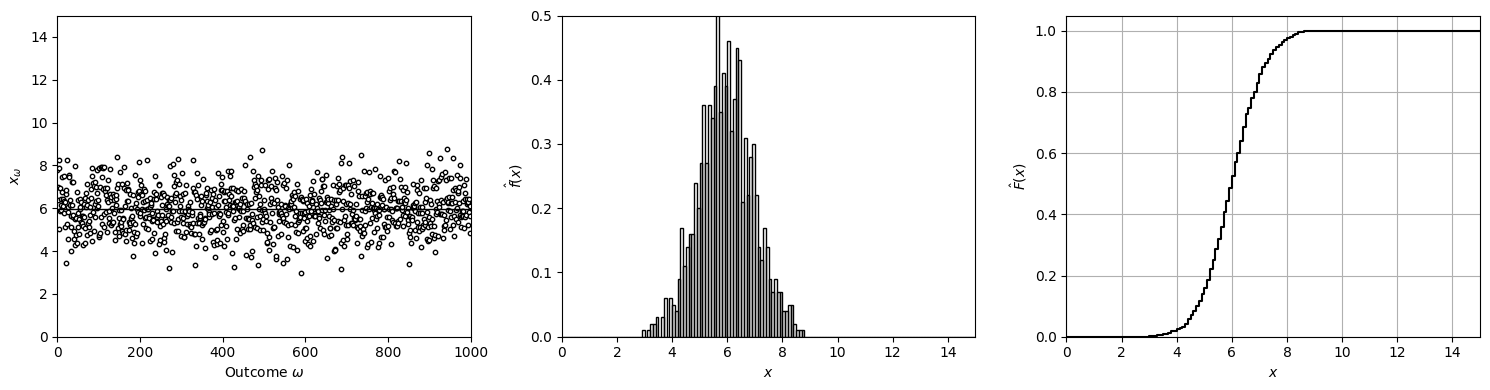

E_hat = 5.95,  V_hat = 0.97,  SD_hat = 0.99


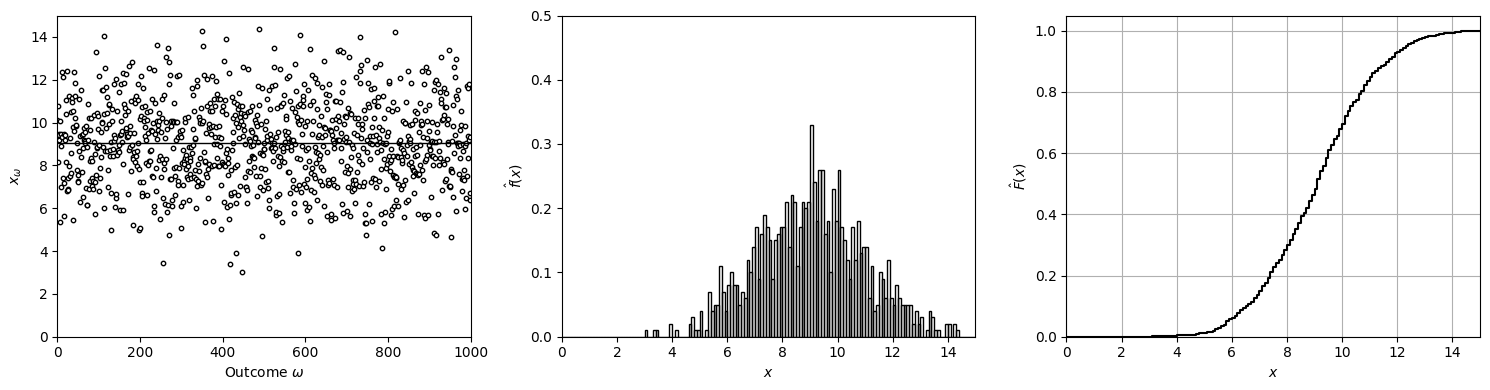

E_hat = 9.03,  V_hat = 3.75,  SD_hat = 1.94


In [2]:
np.random.seed(0)  # reproducibility
S = 1000
dx = 0.1
x_grid = np.arange(0, 15 + dx, dx)

for E_X, SD_X in ((6, 1), (9, 2)):
    x_omega = np.random.normal(E_X, SD_X, S)
    E_hat = np.sum(x_omega) / S                       # (1/S) sum x_omega
    V_hat = np.sum((x_omega - E_hat)**2) / S          # (1/S) sum (x_omega - E_hat)^2
    SD_hat = np.sqrt(V_hat)
    F_hat = np.array([np.mean(x_omega <= x_k) for x_k in x_grid])

    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    axs[0].scatter(np.arange(S), x_omega, marker='o', s=10, color='white', edgecolor='black')
    axs[0].plot([0, S], [E_hat, E_hat], 'k-', linewidth=1)
    axs[0].set_xlabel(r'Outcome $\omega$')
    axs[0].set_ylabel(r'$x_\omega$')
    axs[0].axis([0, S, 0, 15])
    axs[1].hist(x_omega, bins=x_grid, density=True, edgecolor='black', facecolor='none', linewidth=1)
    axs[1].set_xlabel('$x$')
    axs[1].set_ylabel(r'$\hat{f}(x)$')
    axs[1].axis([0, 15, 0, 0.5])
    axs[2].step(x_grid, F_hat, color='black', where='post')
    axs[2].set_xlabel('$x$')
    axs[2].set_ylabel(r'$\hat{F}(x)$')
    axs[2].axis([0, 15, 0, 1.05])
    axs[2].grid(True)
    plt.tight_layout()
    plt.show()
    print(f"E_hat = {E_hat:.2f},  V_hat = {V_hat:.2f},  SD_hat = {SD_hat:.2f}")